# ЛР №4 — прихована структура даних без міток: GMM, KDE, многовиди, профілі

| Розділ | Крок ТЗ |
|---|---|
| 0. Еталон з DVC, запечатування Y, контрольний експеримент, простори ознак | 0 |
| 1. GMM: BIC/AIC, параметри, стабільність, нульова модель, фінальна модель, бутстреп (бонус) | 1 |
| 2. KDE: вибір h крос-валідацією; аномалії KDE / GMM / IsolationForest; Jaccard | 2 |
| 3. PCA / LLE / Isomap / t-SNE; perplexity; trustworthiness; нульова модель; UMAP out-of-sample (бонус) | 3 |
| 4. Профілі кластерів на вихідних ознаках; дві карти ризику | 4 |
| 5. **Запечатаний конверт** — єдине місце, де відкривається Y (бонус) | — |



In [1]:
import sys, os, json, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "spaces.py").exists())
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

from src.data import load_config, load_reference, reference_id, CONFIG
from src.spaces import FeatureSpaces
from src.clustering import (bic_curves, best_by_bic, n_parameters, ari_matrix, mean_offdiag, null_data, fit_final,
                            responsibilities_entropy, bootstrap_stability)
from src.density import scott_bandwidth, select_bandwidth, lowest_share, isolation_scores, jaccard, jaccard_table
from src.manifold import subsample, projections, tsne_perplexities, trust_table
from src.profiles import profile_matrix, top_features, risk_sets

pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
ART, FIG = ROOT / "artifacts", ROOT / "artifacts" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
SEED = 42
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GRAY = "#8a8984"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3",
                     "axes.labelcolor": "#52514e", "text.color": "#0b0b0b", "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "axes.axisbelow": True})
cfg = load_config()
SUMMARY = {}

## 0. Еталон, запечатаний Y, контрольний експеримент, простори

### 0.1. Еталонний знімок через `dvc.api.open`

In [2]:
ref = reference_id(cfg); print(ref)
X_ref_raw, Y_sealed = load_reference(cfg)
print("X_ref_raw:", X_ref_raw.shape, "| запечатано:", Y_sealed.name)
SUMMARY["reference"] = ref

{'rev': None, 'md5': 'c6cfcbbe784ee2407a235ddb309f9736', 'pointer': '/home/roman/machine learning/lab_03/data/raw/lab2_feature_matrix.csv.dvc'}


X_ref_raw:

(1000, 172)

| запечатано:

bad_credit

### 0.2. Контрольний експеримент на синтетиці з відомим Z

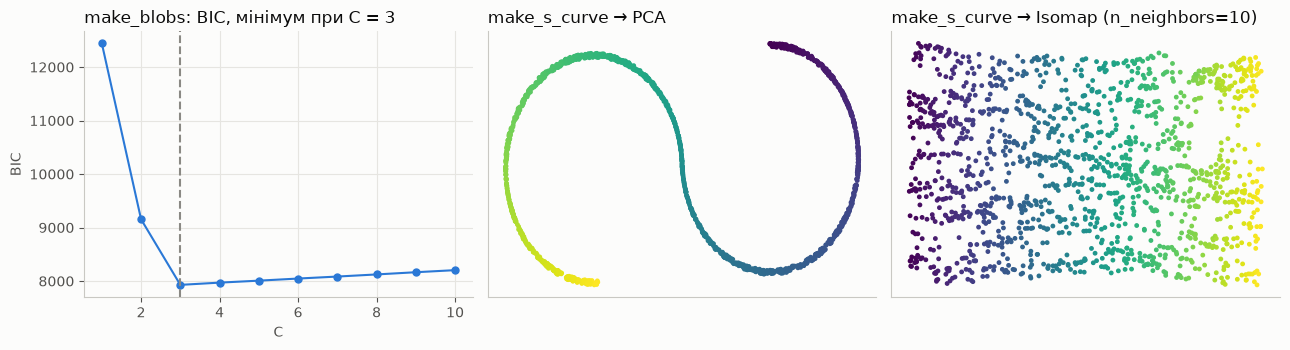

In [3]:
from sklearn.datasets import make_blobs, make_s_curve
from sklearn.manifold import Isomap
from sklearn.decomposition import PCA

Xb, zb = make_blobs(n_samples=1000, centers=3, random_state=SEED)
blob_curve = bic_curves(Xb, (1, 10), ["full"], random_state=SEED)
c_blobs = int(blob_curve.loc[blob_curve.BIC.idxmin(), "C"])
Xs_curve, t_curve = make_s_curve(n_samples=1500, random_state=SEED)
iso_s = Isomap(n_neighbors=10, n_components=2).fit_transform(Xs_curve)
pca_s = PCA(n_components=2, random_state=SEED).fit_transform(Xs_curve)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].plot(blob_curve.C, blob_curve.BIC, "o-", color=PALETTE[0], ms=5)
axes[0].axvline(c_blobs, color=GRAY, ls="--"); axes[0].set_title(f"make_blobs: BIC, мінімум при C = {c_blobs}", loc="left")
axes[0].set_xlabel("C"); axes[0].set_ylabel("BIC")
for ax, Z, name in ((axes[1], pca_s, "PCA"), (axes[2], iso_s, "Isomap (n_neighbors=10)")):
    ax.scatter(Z[:, 0], Z[:, 1], c=t_curve, cmap="viridis", s=6); ax.set_title(f"make_s_curve → {name}", loc="left")
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); fig.savefig(FIG / "control_experiment.png", dpi=130); plt.show()
assert c_blobs == 3, "контрольний експеримент: BIC не відновив 3 кластери"
SUMMARY["control"] = {"blobs_best_C": c_blobs}

### 0.3. Простори ознак


ознак після препроцесора:

219

,простір,розмірність,пояснена дисперсія,вхідна розмірність
0,wide,30,0.7788,219
1,kde,4,0.4029,219


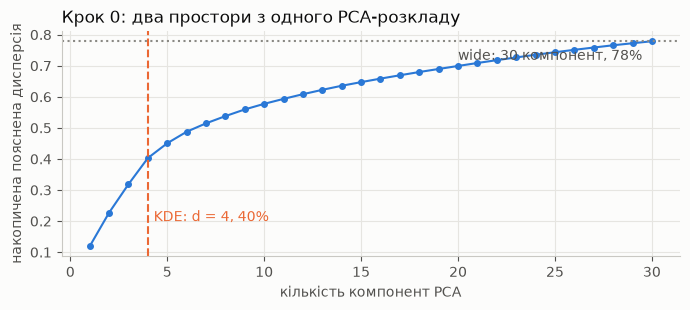

In [4]:
fs = FeatureSpaces.fit(CONFIG, X_ref_raw, cfg)
S = fs.transform(X_ref_raw)
X_scaled, X_wide, X_kde = S["scaled"], S["wide"], S["kde"]
var = fs.variance_table(); var.to_csv(ART / "explained_variance.csv", index=False)
print("ознак після препроцесора:", X_scaled.shape[1])
display(var.round(4))

cum = np.cumsum(fs.pca_wide.explained_variance_ratio_)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(range(1, 31), cum, "o-", color=PALETTE[0], ms=4)
ax.axhline(cum[-1], color=GRAY, ls=":"); ax.axvline(cfg["spaces"]["kde_components"], color=PALETTE[1], ls="--")
ax.text(cfg["spaces"]["kde_components"] + 0.3, 0.2, f"KDE: d = {cfg['spaces']['kde_components']}, {cum[cfg['spaces']['kde_components']-1]:.0%}", color=PALETTE[1])
ax.text(20, cum[-1] - 0.06, f"wide: 30 компонент, {cum[-1]:.0%}", color="#52514e")
ax.set_xlabel("кількість компонент PCA"); ax.set_ylabel("накопичена пояснена дисперсія")
ax.set_title("Крок 0: два простори з одного PCA-розкладу", loc="left")
fig.tight_layout(); fig.savefig(FIG / "explained_variance.png", dpi=130); plt.show()
SUMMARY["spaces"] = var.to_dict("records")

## 1. GMM: вибір C і типу коваріації, стабільність, нульова модель

### 1.1. Криві BIC / AIC (C = 1…15, spherical / diag / full) на X_wide

,covariance,C,BIC,AIC,k,converged
23,diag,9,113317.0,110628.0,548,True
33,full,4,111450.0,101718.0,1983,True
14,spherical,15,115963.0,113612.0,479,True


Мінімум BIC: C = 4, covariance = full; мінімум AIC: C = 15, full

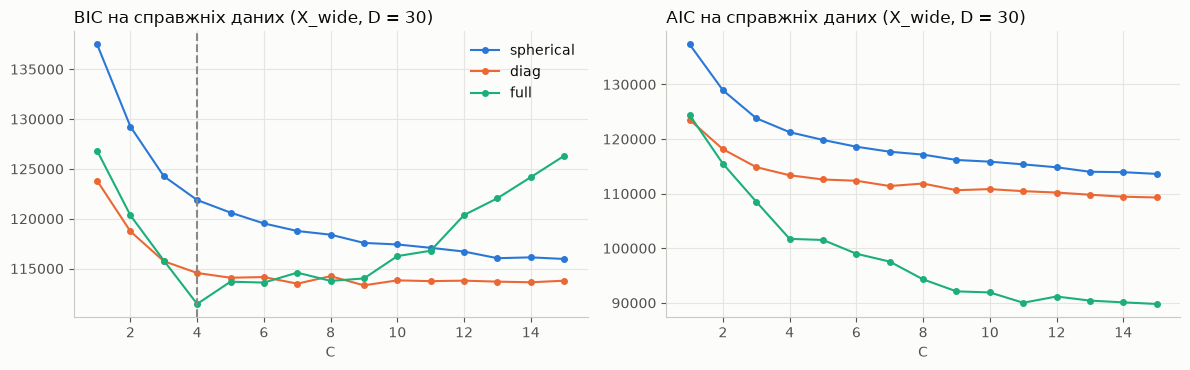

In [5]:
g = cfg["gmm"]
curves = bic_curves(X_wide, tuple(g["c_range"]), g["covariance_types"], random_state=SEED)
curves.to_csv(ART / "bic_curves.csv", index=False)
C_best, COV_best = best_by_bic(curves)
D = X_wide.shape[1]
best_rows = curves.loc[curves.groupby("covariance")["BIC"].idxmin()]
display(best_rows[["covariance", "C", "BIC", "AIC", "k", "converged"]].round(0))
print(f"Мінімум BIC: C = {C_best}, covariance = {COV_best}; мінімум AIC: "
      f"C = {int(curves.loc[curves.AIC.idxmin(), 'C'])}, {curves.loc[curves.AIC.idxmin(), 'covariance']}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
for ax, crit in zip(axes, ("BIC", "AIC")):
    for i, cov in enumerate(g["covariance_types"]):
        sub = curves[curves.covariance == cov]
        ax.plot(sub.C, sub[crit], "o-", ms=4, color=PALETTE[i], label=cov)
    ax.set_title(f"{crit} на справжніх даних (X_wide, D = {D})", loc="left"); ax.set_xlabel("C")
axes[0].axvline(C_best, color=GRAY, ls="--"); axes[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "bic_aic_curves.png", dpi=130); plt.show()

### 1.2. Кількість параметрів обраної моделі

In [6]:
k_full = n_parameters(C_best, D, COV_best)
per_cov = {"spherical": C_best, "diag": C_best * D, "full": C_best * D * (D + 1) // 2}
print(f"k = C·D + (C − 1) + cov = {C_best}·{D} + {C_best - 1} + {per_cov[COV_best]} = {k_full}   ({COV_best})")
print("параметрів коваріації для кожного типу при C =", C_best, ":", per_cov)
print(f"штраф BIC = ln(n)·k = ln({len(X_wide)})·{k_full} = {np.log(len(X_wide)) * k_full:,.0f};  штраф AIC = 2·k = {2 * k_full:,}")
SUMMARY["gmm"] = {"C": C_best, "covariance": COV_best, "k": int(k_full), "D": int(D),
                  "bic_min": float(curves.BIC.min())}

k = C·D + (C − 1) + cov = 4·30 + 3 + 1860 = 1983   (full)

параметрів коваріації для кожного типу при C =

4

:

{'spherical': 4, 'diag': 120, 'full': 1860}

штраф BIC = ln(n)·k = ln(1000)·1983 = 13,698;  штраф AIC = 2·k = 3,966

### 1.3. Стабільність розбиття


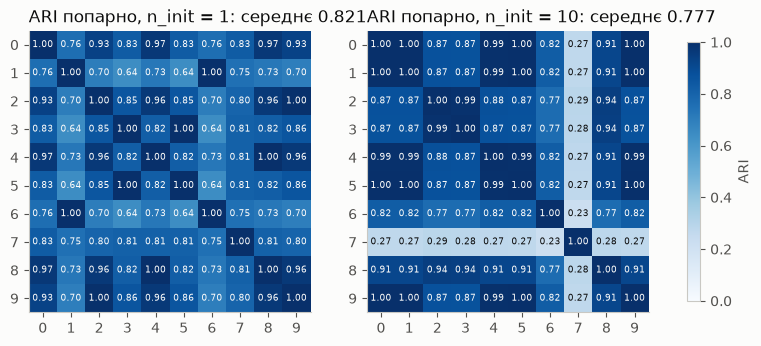

середній ARI: n_init=1 → 0.821, n_init=10 → 0.777; поріг 0.8 → стабільно

In [7]:
m1 = ari_matrix(X_wide, C_best, COV_best, n_init=1, seeds=g["stability_seeds"])
m10 = ari_matrix(X_wide, C_best, COV_best, n_init=10, seeds=g["stability_seeds"])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, m, title in ((axes[0], m1, "n_init = 1"), (axes[1], m10, "n_init = 10")):
    im = ax.imshow(m, vmin=0, vmax=1, cmap="Blues"); ax.set_title(f"ARI попарно, {title}: середнє {mean_offdiag(m):.3f}", loc="left")
    ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.grid(False)
    for i in range(10):
        for j in range(10):
            ax.text(j, i, f"{m[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color="#0b0b0b" if m[i, j] < 0.6 else "#fcfcfb")
fig.colorbar(im, ax=axes, shrink=0.8, label="ARI")
fig.savefig(FIG / "ari_matrix.png", dpi=130, bbox_inches="tight"); plt.show()
stable = mean_offdiag(m1) >= g["ari_threshold"]
print(f"середній ARI: n_init=1 → {mean_offdiag(m1):.3f}, n_init=10 → {mean_offdiag(m10):.3f}; "
      f"поріг {g['ari_threshold']} → {'стабільно' if stable else 'НЕстабільно'}")
SUMMARY["gmm"].update({"ari_ninit1": mean_offdiag(m1), "ari_ninit10": mean_offdiag(m10), "stable": bool(stable)})

Для порівняння — та сама діагностика для сусідніх C і для diag-альтернативи:

In [8]:
alt = []
for c, cov in ((C_best - 1, COV_best), (C_best + 1, COV_best), (int(best_rows.set_index("covariance").loc["diag", "C"]), "diag")):
    if c >= 1:
        alt.append({"C": c, "covariance": cov, "ARI n_init=1": mean_offdiag(ari_matrix(X_wide, c, cov, 1, 10)),
                    "BIC": float(curves.set_index(["covariance", "C"]).loc[(cov, c), "BIC"])})
alt = pd.DataFrame(alt); alt.to_csv(ART / "stability_alternatives.csv", index=False); alt.round(3)

,C,covariance,ARI n_init=1,BIC
0,3,full,0.622,115809.058
1,5,full,0.705,113685.308
2,9,diag,0.812,113317.246


### 1.4. Нульова модель


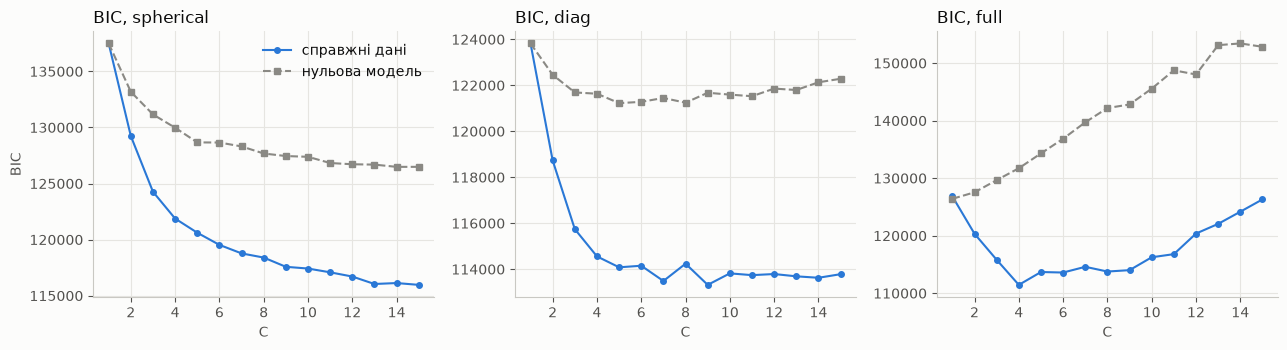

нульова модель: мінімум BIC при C = 5 (diag), BIC = 121,223; справжні дані: C = 4 (full), BIC = 111,450; різниця 9,773

In [9]:
X_null = null_data(X_wide, random_state=SEED)
curves_null = bic_curves(X_null, tuple(g["c_range"]), g["covariance_types"], random_state=SEED)
curves_null.to_csv(ART / "bic_curves_null.csv", index=False)
C_null, COV_null = best_by_bic(curves_null)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=False)
for ax, cov in zip(axes, g["covariance_types"]):
    r, n = curves[curves.covariance == cov], curves_null[curves_null.covariance == cov]
    ax.plot(r.C, r.BIC, "o-", ms=4, color=PALETTE[0], label="справжні дані")
    ax.plot(n.C, n.BIC, "s--", ms=4, color=GRAY, label="нульова модель")
    ax.set_title(f"BIC, {cov}", loc="left"); ax.set_xlabel("C")
axes[0].set_ylabel("BIC"); axes[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "bic_null_model.png", dpi=130); plt.show()
print(f"нульова модель: мінімум BIC при C = {C_null} ({COV_null}), BIC = {curves_null.BIC.min():,.0f}; "
      f"справжні дані: C = {C_best} ({COV_best}), BIC = {curves.BIC.min():,.0f}; різниця {curves_null.BIC.min() - curves.BIC.min():,.0f}")
SUMMARY["null"] = {"C": C_null, "covariance": COV_null, "bic_min": float(curves_null.BIC.min())}

### 1.5. Фінальна модель (n_init = 10) і бонус — бутстреп-стабільність

In [10]:
gmm = fit_final(X_wide, C_best, COV_best, random_state=SEED)
gamma = gmm.predict_proba(X_wide); labels = gmm.predict(X_wide)
sizes = pd.Series(labels).value_counts().sort_index()
print("розміри кластерів:", sizes.to_dict(), "| ваги GMM:", gmm.weights_.round(3))
np.save(ART / "gmm_labels.npy", labels); np.save(ART / "gmm_responsibilities.npy", gamma)

boot = bootstrap_stability(X_wide, labels, C_best, COV_best, n_resamples=g["bootstrap_resamples"], random_state=SEED)
boot.to_csv(ART / "bootstrap_stability.csv", index=False)
print(f"бутстреп ({g['bootstrap_resamples']} вибірок): ARI з фінальною моделлю {boot.ARI_vs_final.mean():.3f} ± {boot.ARI_vs_final.std(ddof=1):.3f}, "
      f"min {boot.ARI_vs_final.min():.3f}")
SUMMARY["gmm"].update({"sizes": sizes.to_dict(), "bootstrap_ari_mean": float(boot.ARI_vs_final.mean()),
                       "bootstrap_ari_sd": float(boot.ARI_vs_final.std(ddof=1))})

розміри кластерів:

{0: 42, 1: 562, 2: 198, 3: 198}

| ваги GMM:

[0.042 0.563 0.198 0.197]

бутстреп (20 вибірок): ARI з фінальною моделлю 0.727 ± 0.161, min 0.281

## 2. KDE і аномалії за густиною

### 2.1. Вибір h: правило Скотта як старт, логарифмічна сітка 0.2×…5×, `GridSearchCV` з `KFold(5, shuffle, 42)`

KDE — лише на X_kde (d = 4).

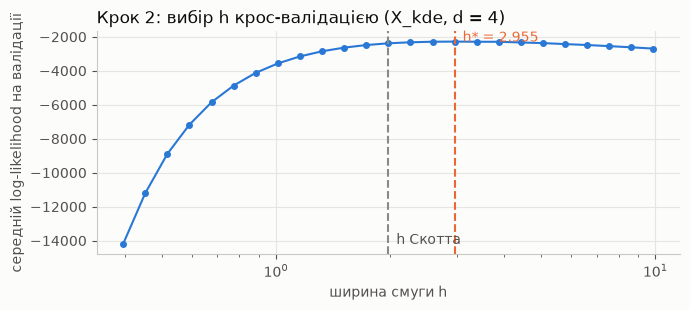

h Скотта = 1.976; h* (CV) = 2.955 (×1.50); сітка 0.395…9.880, 25 точок

In [11]:
k = cfg["kde"]
search = select_bandwidth(X_kde, factors=tuple(k["grid_factors"]), points=k["grid_points"], folds=k["cv_folds"], random_state=SEED)
h_best = search.best_params_["bandwidth"]
res = pd.DataFrame(search.cv_results_)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(res.param_bandwidth.astype(float), res.mean_test_score, "o-", ms=4, color=PALETTE[0])
ax.axvline(search.h_scott_, color=GRAY, ls="--"); ax.text(search.h_scott_ * 1.05, res.mean_test_score.min(), "h Скотта", color="#52514e")
ax.axvline(h_best, color=PALETTE[1], ls="--"); ax.text(h_best * 1.05, res.mean_test_score.max() - 0.3, f"h* = {h_best:.3f}", color=PALETTE[1])
ax.set_xscale("log"); ax.set_xlabel("ширина смуги h"); ax.set_ylabel("середній log-likelihood на валідації")
ax.set_title("Крок 2: вибір h крос-валідацією (X_kde, d = 4)", loc="left")
fig.tight_layout(); fig.savefig(FIG / "kde_bandwidth.png", dpi=130); plt.show()
print(f"h Скотта = {search.h_scott_:.3f}; h* (CV) = {h_best:.3f} (×{h_best / search.h_scott_:.2f}); сітка {res.param_bandwidth.min():.3f}…{res.param_bandwidth.max():.3f}, {len(res)} точок")
SUMMARY["kde"] = {"h_scott": float(search.h_scott_), "h_best": float(h_best), "d": int(X_kde.shape[1])}

### 2.2. Три множини аномалій (5% найменших `score_samples`) і Jaccard

In [12]:
share = k["anomaly_share"]
logp_kde = search.best_estimator_.score_samples(X_kde)
logp_gmm = gmm.score_samples(X_wide)
score_if = isolation_scores(X_wide, contamination=share, random_state=SEED)
A_sets = {"KDE (d=4)": lowest_share(logp_kde, share), "GMM (D=30)": lowest_share(logp_gmm, share), "IsolationForest (D=30)": lowest_share(score_if, share)}
J = jaccard_table(A_sets); J.to_csv(ART / "jaccard_anomalies.csv")
np.save(ART / "scores_kde_gmm_if.npy", np.column_stack([logp_kde, logp_gmm, score_if]))
print("розмір кожної множини:", {n: len(s) for n, s in A_sets.items()})
display(J.round(3))
print("кластери аномалій GMM:", pd.Series(labels[list(A_sets["GMM (D=30)"])]).value_counts().sort_index().to_dict())
SUMMARY["anomalies"] = {"jaccard": {a: {b: float(J.loc[a, b]) for b in J.columns} for a in J.index}}

розмір кожної множини:

{'KDE (d=4)': 50, 'GMM (D=30)': 50, 'IsolationForest (D=30)': 50}

,KDE (d=4),GMM (D=30),IsolationForest (D=30)
KDE (d=4),1.000,0.282,0.370
GMM (D=30),0.282,1.000,0.389
IsolationForest (D=30),0.370,0.389,1.000


кластери аномалій GMM:

{1: 4, 2: 5, 3: 41}

## 3. Навчання многовидів

### 3.1. Одна підвибірка (≤ 3000 точок) і сітка 2×2


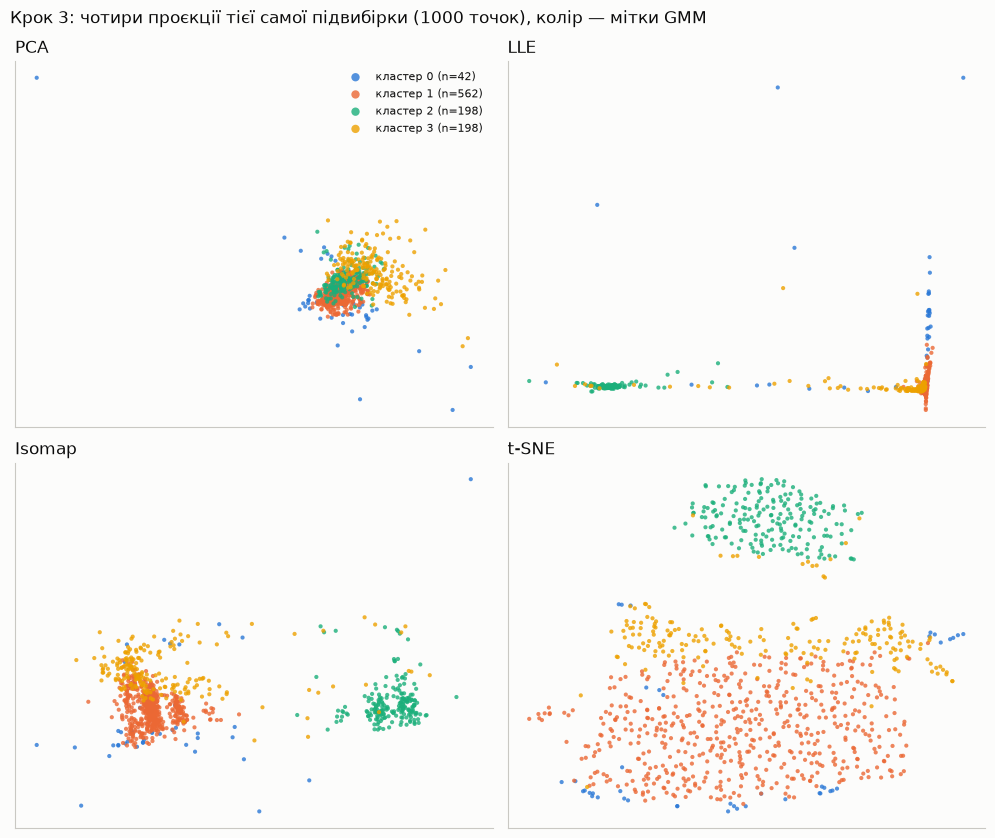

підвибірка:

1000

точок (усі)

In [13]:
mf = cfg["manifold"]
idx = subsample(len(X_wide), mf["max_points"], random_state=SEED)
Xm, lab_m = X_wide[idx], labels[idx]
emb = projections(Xm, n_neighbors=mf["n_neighbors"], perplexity=mf["tsne_default_perplexity"], random_state=SEED)
fig, axes = plt.subplots(2, 2, figsize=(10, 8.5))
for ax, (name, Z) in zip(axes.ravel(), emb.items()):
    for c in range(C_best):
        m = lab_m == c
        ax.scatter(Z[m, 0], Z[m, 1], s=9, color=PALETTE[c], label=f"кластер {c} (n={m.sum()})", alpha=0.8, edgecolors="none")
    ax.set_title(name, loc="left"); ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].legend(frameon=False, fontsize=8, markerscale=2)
fig.suptitle(f"Крок 3: чотири проєкції тієї самої підвибірки ({len(idx)} точок), колір — мітки GMM", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "projections_2x2.png", dpi=130); plt.show()
print("підвибірка:", len(idx), "точок (усі)")

### 3.2. Чутливість t-SNE до perplexity (5, 30, 50)

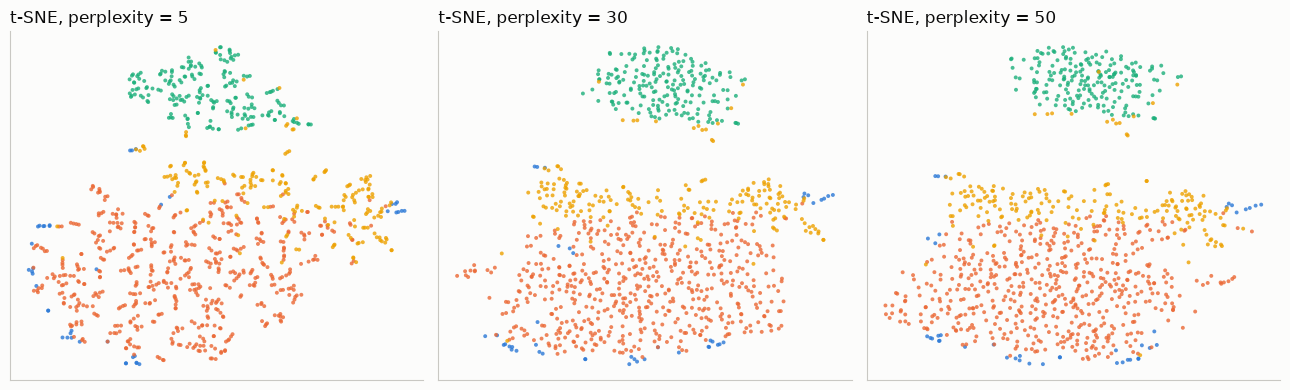

In [14]:
ts = tsne_perplexities(Xm, mf["tsne_perplexities"], random_state=SEED)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (p, Z) in zip(axes, ts.items()):
    for c in range(C_best):
        m = lab_m == c; ax.scatter(Z[m, 0], Z[m, 1], s=8, color=PALETTE[c], alpha=0.8, edgecolors="none")
    ax.set_title(f"t-SNE, perplexity = {p}", loc="left"); ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); fig.savefig(FIG / "tsne_perplexity.png", dpi=130); plt.show()

### 3.3. Trustworthiness (n_neighbors = 10) для чотирьох проєкцій і трьох perplexity

In [15]:
all_emb = dict(emb); all_emb.update({f"t-SNE p={p}": Z for p, Z in ts.items()})
trust = trust_table(Xm, all_emb, n_neighbors=mf["n_neighbors"]); trust.to_csv(ART / "trustworthiness.csv", index=False)
trust.round(4)

,проєкція,trustworthiness
0,t-SNE p=50,0.9503
1,t-SNE,0.9487
2,t-SNE p=30,0.9487
3,t-SNE p=5,0.9318
4,Isomap,0.8175
5,LLE,0.7764
6,PCA,0.7673


### 3.4. Нульова модель на t-SNE (опційно): X_null з кроку 1 у тому самому режимі

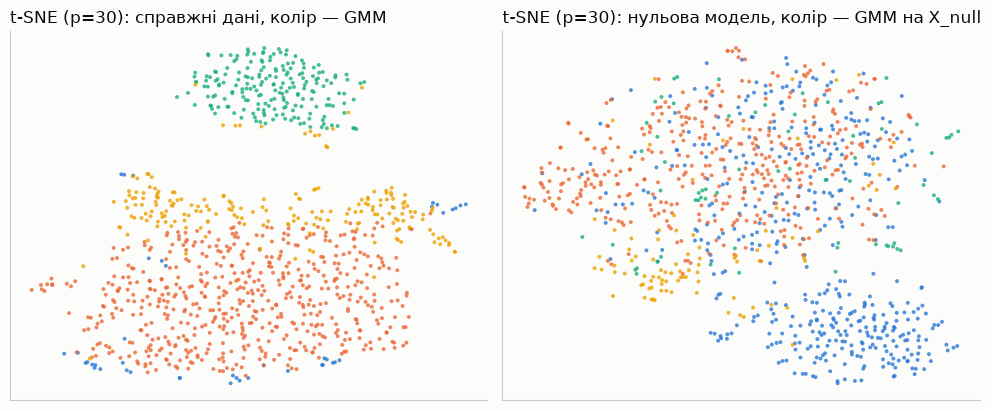

In [16]:
from sklearn.manifold import TSNE
Z_null = TSNE(n_components=2, init="pca", perplexity=mf["tsne_default_perplexity"], random_state=SEED).fit_transform(X_null[idx])
lab_null = GaussianMixture(C_best, covariance_type=COV_best, n_init=10, random_state=SEED).fit_predict(X_null[idx])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, Z, lab, title in ((axes[0], emb["t-SNE"], lab_m, "справжні дані, колір — GMM"), (axes[1], Z_null, lab_null, "нульова модель, колір — GMM на X_null")):
    for c in range(C_best):
        m = lab == c; ax.scatter(Z[m, 0], Z[m, 1], s=8, color=PALETTE[c], alpha=0.8, edgecolors="none")
    ax.set_title(f"t-SNE (p=30): {title}", loc="left"); ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); fig.savefig(FIG / "tsne_null_model.png", dpi=130); plt.show()
SUMMARY["manifold"] = {"n_points": int(len(idx)), "trustworthiness": trust.set_index("проєкція")["trustworthiness"].round(4).to_dict()}

### 3.5. Бонус: UMAP out-of-sample


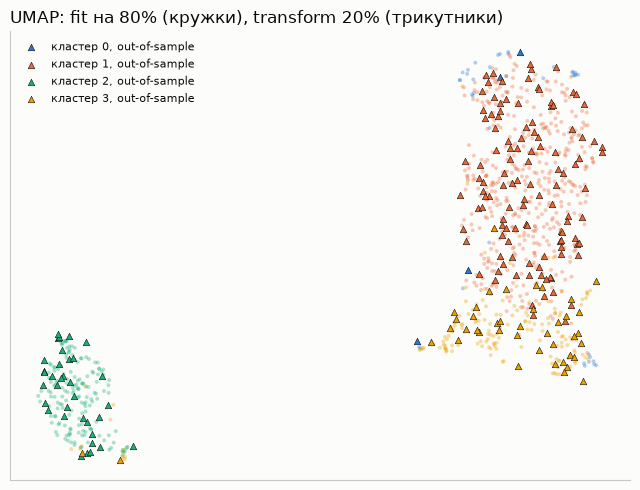

UMAP trustworthiness:

{'train': np.float64(0.9164), 'out_of_sample': np.float64(0.9044)}

In [17]:
import umap
from sklearn.manifold import trustworthiness
rng = np.random.default_rng(SEED)
train_mask = rng.random(len(Xm)) < 0.8
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED).fit(Xm[train_mask])
Z_tr, Z_te = reducer.embedding_, reducer.transform(Xm[~train_mask])
fig, ax = plt.subplots(figsize=(6.5, 5))
for c in range(C_best):
    m = lab_m[train_mask] == c; ax.scatter(Z_tr[m, 0], Z_tr[m, 1], s=8, color=PALETTE[c], alpha=0.35, edgecolors="none")
    m2 = lab_m[~train_mask] == c; ax.scatter(Z_te[m2, 0], Z_te[m2, 1], s=22, color=PALETTE[c], marker="^", edgecolors="#0b0b0b", linewidths=0.4, label=f"кластер {c}, out-of-sample")
ax.legend(frameon=False, fontsize=8); ax.set_xticks([]); ax.set_yticks([])
ax.set_title("UMAP: fit на 80% (кружки), transform 20% (трикутники)", loc="left")
fig.tight_layout(); fig.savefig(FIG / "umap_out_of_sample.png", dpi=130); plt.show()
t_umap = {"train": trustworthiness(Xm[train_mask], Z_tr, n_neighbors=10), "out_of_sample": trustworthiness(Xm[~train_mask], Z_te, n_neighbors=10)}
print("UMAP trustworthiness:", {k: round(v, 4) for k, v in t_umap.items()})
SUMMARY["umap"] = t_umap

## 4. Профілі кластерів і дві карти ризику

### 4.1. Профілі на вихідних ознаках X_ref_raw



In [18]:
feats = cfg["features"]
numeric_cols = feats["numeric_continuous"] + feats["numeric_discrete"] + feats["payment_signal"] + feats["dfs_features"]
categorical_cols = feats["categorical_nominal"] + feats["categorical_ordinal"]
prof = profile_matrix(X_ref_raw, labels, numeric_cols, categorical_cols); prof.to_csv(ART / "cluster_profiles.csv", index=False)
top = pd.concat([top_features(prof, c, cfg["profiles"]["top_k"]) for c in range(C_best)])
top["size"] = top["cluster"].map(sizes)
top.to_csv(ART / "cluster_top_features.csv", index=False)
top.round(3)

,cluster,feature,kind,value,cluster_stat,global_stat,size
129,0,credit_amount_div_COUNT_payments,z,2.869,641.427,96.214,42
95,0,MEAN_payments_AMT_INSTALMENT_div_COUNT_payments,z,2.685,2883.148,529.009,42
104,0,MEAN_payments_AMT_PAYMENT_div_COUNT_payments,z,2.642,2882.592,533.233,42
8,0,sig_mfcc0,z,-2.626,-28.663,57.388,42
132,0,credit_amount_div_MAX_payments_NUM_INSTALMENT_...,z,2.169,754.500,165.600,42
483,1,duration_div_MAX_payments_AMT_INSTALMENT,z,0.261,0.001,0.000,562
443,1,MEAN_payments_AMT_INSTALMENT_div_MAX_payments_...,z,0.254,0.483,0.332,562
484,1,duration_div_MAX_payments_AMT_PAYMENT,z,0.252,0.001,0.000,562
452,1,MEAN_payments_AMT_PAYMENT_div_MAX_payments_AMT...,z,0.252,0.469,0.332,562
451,1,MEAN_payments_AMT_PAYMENT_div_MAX_payments_AMT...,z,0.248,0.475,0.339,562


**Назви кластерів** (за топ-5 ознаками; заповнено після перегляду профілів):

In [19]:
CLUSTER_NAMES = json.loads((ROOT / "config" / "cluster_names.json").read_text(encoding="utf-8")) if (ROOT / "config" / "cluster_names.json").exists() else {}
summary_tab = pd.DataFrame([{"кластер": c, "розмір": int(sizes[c]),
                             "топ-5 (ознака: значення)": "; ".join(f"{r.feature}: {r.value:+.2f}" for r in top[top.cluster == c].itertuples()),
                             "назва": CLUSTER_NAMES.get(str(c), "—")} for c in range(C_best)])
summary_tab.to_csv(ART / "cluster_summary.csv", index=False)
pd.set_option("display.max_colwidth", 200); summary_tab

,кластер,розмір,топ-5 (ознака: значення),назва
0,0,42,credit_amount_div_COUNT_payments: +2.87; MEAN_payments_AMT_INSTALMENT_div_COUNT_payments: +2.68; MEAN_payments_AMT_PAYMENT_div_COUNT_payments: +2.64; sig_mfcc0: -2.63; credit_amount_div_MAX_paymen...,"Коротка платіжна історія: мало внесків Home Credit (медіана 6), тому відношення «сума / кількість внесків» великі; великий кредит (медіана 5 763 DM); тихий сигнал запізнень"
1,1,562,duration_div_MAX_payments_AMT_INSTALMENT: +0.26; MEAN_payments_AMT_INSTALMENT_div_MAX_payments_AMT_PAYMENT: +0.25; duration_div_MAX_payments_AMT_PAYMENT: +0.25; MEAN_payments_AMT_PAYMENT_div_MAX_p...,"Типова заявка: усі ознаки біля загальної медіани, ~20 внесків, помірні суми — «фон» вибірки"
2,2,198,MEAN_payments_NUM_INSTALMENT_NUMBER_div_credit_amount (пропуск): +0.78; credit_amount_div_MEAN_payments_NUM_INSTALMENT_NUMBER (пропуск): +0.78; credit_amount_div_MEAN_payments_AMT_PAYMENT (пропуск...,"Заявки без суми кредиту: 92% пропусків credit_amount (MCAR-інжектування ЛР №1) — кластер, заданий індикаторами пропуску імпутера, а не поведінкою заявника"
3,3,198,MAX_payments_NUM_INSTALMENT_NUMBER_div_AMT_INSTALMENT: +14.35; MAX_payments_AMT_PAYMENT_div_credit_amount: +2.61; MAX_payments_AMT_INSTALMENT_div_credit_amount: +2.55; MAX_payments_AMT_INSTALMENT:...,"Велика платіжна історія Home Credit: ~70 внесків, максимальні внески в 10 разів більші за медіану — важкий хвіст, де лежать 41 з 50 аномалій GMM"


### 4.2. Дві карти ризику




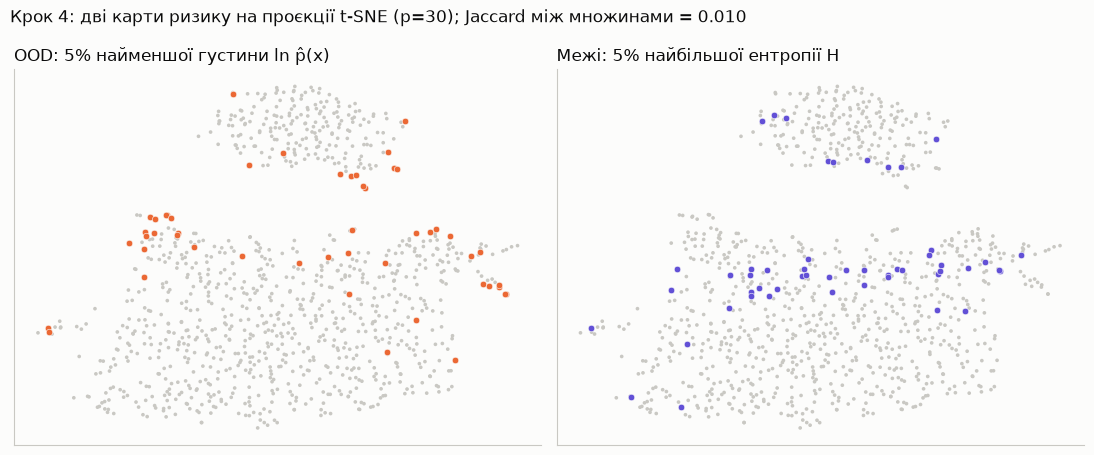

Jaccard(OOD, межі) = 0.010; |перетин| = 1

ентропія: медіана 0.000, max 0.679 (максимум ln C = 1.386); частка точок з H < 0.01: 95.90%

середня H серед OOD-точок:

0.0

| середня ln p̂ серед точок високої ентропії:

-53.4

| медіана ln p̂ загалом:

-45.4

In [20]:
H = responsibilities_entropy(gamma)
R = risk_sets(logp_gmm, H, cfg["profiles"]["risk_share"])
J_risk = jaccard(R["low_density"], R["high_entropy"])
Z = emb["t-SNE"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, key, title, color in ((axes[0], "low_density", "OOD: 5% найменшої густини ln p̂(x)", PALETTE[1]),
                              (axes[1], "high_entropy", "Межі: 5% найбільшої ентропії H", PALETTE[6])):
    ax.scatter(Z[:, 0], Z[:, 1], s=7, color="#c9c8c3", edgecolors="none")
    sel = np.array(sorted(R[key])); ax.scatter(Z[sel, 0], Z[sel, 1], s=22, color=color, edgecolors="#fcfcfb", linewidths=0.4)
    ax.set_title(title, loc="left"); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"Крок 4: дві карти ризику на проєкції t-SNE (p=30); Jaccard між множинами = {J_risk:.3f}", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "risk_maps.png", dpi=130); plt.show()
print(f"Jaccard(OOD, межі) = {J_risk:.3f}; |перетин| = {len(R['low_density'] & R['high_entropy'])}")
print(f"ентропія: медіана {np.median(H):.3f}, max {H.max():.3f} (максимум ln C = {np.log(C_best):.3f}); "
      f"частка точок з H < 0.01: {(H < 0.01).mean():.2%}")
print("середня H серед OOD-точок:", round(H[sorted(R["low_density"])].mean(), 3), "| середня ln p̂ серед точок високої ентропії:",
      round(logp_gmm[sorted(R["high_entropy"])].mean(), 1), "| медіана ln p̂ загалом:", round(np.median(logp_gmm), 1))
SUMMARY["risk"] = {"jaccard": float(J_risk), "overlap": len(R["low_density"] & R["high_entropy"]),
                   "entropy_median": float(np.median(H)), "entropy_max": float(H.max())}

### 4.3. Доповнення: чи структура зумовлена блоком платежів Home Credit?


In [21]:
import tempfile, yaml
german_groups = ["numeric_continuous", "numeric_discrete", "categorical_nominal", "categorical_ordinal"]
cfg_g = json.loads(json.dumps(cfg))
cfg_g["features"] = {g: cfg["features"][g] for g in german_groups}
cfg_g["imputation_routing"] = {g: cfg["imputation_routing"][g] for g in german_groups}
cfg_g["transform_policy"] = {"additive": {g: cfg["transform_policy"]["additive"][g] for g in german_groups}}
cfg_g["spaces"]["wide_components"] = 20
f = tempfile.NamedTemporaryFile("w", suffix=".yaml", delete=False, encoding="utf-8"); yaml.safe_dump(cfg_g, f, allow_unicode=True); f.close()
fs_g = FeatureSpaces.fit(f.name, X_ref_raw, cfg_g); Sg = fs_g.transform(X_ref_raw)
curves_g = bic_curves(Sg["wide"], (1, 15), g["covariance_types"], random_state=SEED)
Cg, COVg = best_by_bic(curves_g)
ari_g1 = mean_offdiag(ari_matrix(Sg["wide"], Cg, COVg, n_init=1, seeds=10))
labels_g = fit_final(Sg["wide"], Cg, COVg, random_state=SEED).predict(Sg["wide"])
print(f"German Credit без платіжного блоку: {Sg['wide'].shape[1]} компонент PCA пояснюють {fs_g.pca_wide.explained_variance_ratio_.sum():.1%} "
      f"з {Sg['scaled'].shape[1]} ознак; мінімум BIC при C = {Cg} ({COVg}); ARI стабільності n_init=1 = {ari_g1:.3f}")
print(f"ARI(мітки повного простору, мітки German-only) = {adjusted_rand_score(labels, labels_g):.3f}")
pd.crosstab(pd.Series(labels, name="повний простір"), pd.Series(labels_g, name="German-only"))

German Credit без платіжного блоку: 20 компонент PCA пояснюють 67.7% з 52 ознак; мінімум BIC при C = 5 (full); ARI стабільності n_init=1 = 0.338

ARI(мітки повного простору, мітки German-only) = 0.020

German-only,0,1,2,3,4
повний простір,,,,,
0,19,8,5,3,7
1,209,72,76,161,44
2,55,30,42,50,21
3,62,32,36,47,21


In [22]:
groups = {"German Credit": [n for n in fs.feature_names if n.split("__")[0] in german_groups],
          "сигнал Home Credit": [n for n in fs.feature_names if n.startswith("payment_signal__")],
          "DFS платежів": [n for n in fs.feature_names if n.startswith("dfs_features__")],
          "час скарги": [n for n in fs.feature_names if n.startswith("complaint_time__")]}
load = pd.DataFrame(fs.pca_wide.components_ ** 2, columns=fs.feature_names)
contrib = pd.DataFrame({name: load[cols].sum(axis=1) * fs.pca_wide.explained_variance_ratio_ for name, cols in groups.items()})
share = (contrib.sum() / contrib.sum().sum()).rename("частка поясненої дисперсії X_wide").to_frame()
share["ознак у блоці"] = [len(c) for c in groups.values()]
SUMMARY["blocks"] = {"variance_share": share.iloc[:, 0].round(4).to_dict(), "german_only": {"C": Cg, "covariance": COVg, "ari_ninit1": ari_g1,
                     "ari_vs_full": float(adjusted_rand_score(labels, labels_g))}}
share.round(3)

,частка поясненої дисперсії X_wide,ознак у блоці
German Credit,0.160,52
сигнал Home Credit,0.069,15
DFS платежів,0.768,148
час скарги,0.003,4


## 5. Запечатаний конверт (бонус) — Y відкривається лише тут


In [23]:
Y = Y_sealed.to_numpy()
ari_y = adjusted_rand_score(Y, labels)
print(f"ARI(GMM German-only, Y) = {adjusted_rand_score(Y, labels_g):.4f}")
ct = pd.crosstab(pd.Series(labels, name="кластер GMM"), pd.Series(Y, name="bad_credit"), margins=True)
ct["частка bad"] = (ct[1] / ct["All"]).round(3)
display(ct)
print(f"ARI(GMM, Y) = {ari_y:.4f}; базова частка bad = {Y.mean():.3f}")
SUMMARY["envelope"] = {"ari": float(ari_y), "ari_german_only": float(adjusted_rand_score(Y, labels_g)), "bad_share_by_cluster": ct["частка bad"].iloc[:-1].to_dict()}
(ART / "summary.json").write_text(json.dumps(SUMMARY, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
print("артефакти збережено")

ARI(GMM German-only, Y) = 0.0271

bad_credit,0,1,All,частка bad
кластер GMM,,,,
0,29,13,42,0.310
1,392,170,562,0.302
2,133,65,198,0.328
3,146,52,198,0.263
All,700,300,1000,0.300


ARI(GMM, Y) = -0.0017; базова частка bad = 0.300

артефакти збережено